# Gold forecasting with Prophet

Prophet fits log gold prices with trend, weekly and yearly seasonality.
Gold-derived regressors are excluded. External regressors use their origin-time values throughout
each fixed-origin forecast. These are conditional persistence scenarios, not known future factors.

Run notebook 01 first. Review the shared audit and release assumptions before interpreting errors.

In [19]:
from pathlib import Path
import os
# Limit CPU threads before importing optional numerical/model libraries.
os.environ.setdefault('TF_CPP_MIN_LOG_LEVEL', '2')
os.environ.setdefault('TF_NUM_INTRAOP_THREADS', '2')
os.environ.setdefault('TF_NUM_INTEROP_THREADS', '1')
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from gold_common_utils import ROOT, load_config
# Load the shared experiment configuration.
cfg = load_config()
pd.set_option('display.max_columns', 20)
print('Project:', ROOT)
print('Target:', cfg['target_name'], '| horizons:', cfg['horizons'])

Project: /home/kosala/git-repos/exps/gold_forecasting
Target: Kitco Price (USD) | horizons: [1, 5, 20]


## 1. Load the shared panel and evaluation contract

In [20]:
from gold_common_utils import load_prepared, feature_columns, forecast_origins, metrics
from gold_model_utils import (DEFAULT_TRIALS, run_cross_validation, evaluate_holdout,
                              refit_and_forecast, fit_model, predict_model)
KIND = 'prophet'
# Reuse the processed data and folds created by notebook 01.
panel, features, folds = load_prepared()
display(folds)
print('Observed target:', panel.y.notna().sum())

,fold,cutoff,stop
0,cv_1,2175,2301
1,cv_2,2301,2427
2,cv_3,2427,2553
3,cv_4,2553,2679
4,cv_5,2679,2805
5,holdout,2805,3057


Observed target: 2646


## 2. Inspect input feature groups and candidate settings
`gold_only` establishes whether external factors improve an already useful gold-history model.
The initial search is intentionally small; expand it using development results only.
All candidate selection uses earlier inner validation. Read the adapters in `gold_model_utils.py`
for the explicit training and prediction logic.

In [21]:
# Show the exact candidates and the feature columns used per group.
trials = [dict(trial) for trial in DEFAULT_TRIALS[KIND]]
display(pd.DataFrame(trials))
for group in ['gold_only', 'external']:
    print(group, feature_columns(features, group, KIND))
# Change this local list to add candidates; keep comparable GRU/LSTM budgets.

,group,changepoint_prior_scale
0,gold_only,0.05
1,external,0.05
2,external,0.20


gold_only []
external ['dxy', 'fed', 'yield10', 'cpi_yoy', 'gpr_ma7', 'brent_spot', 'wti']


## 3. Inspect observed target and regressor coverage

,missing_fraction
dxy,0.000000
fed,0.000000
yield10,0.000000
cpi_yoy,0.005232
gpr_ma7,0.000000
brent_spot,0.000000
wti,0.000000


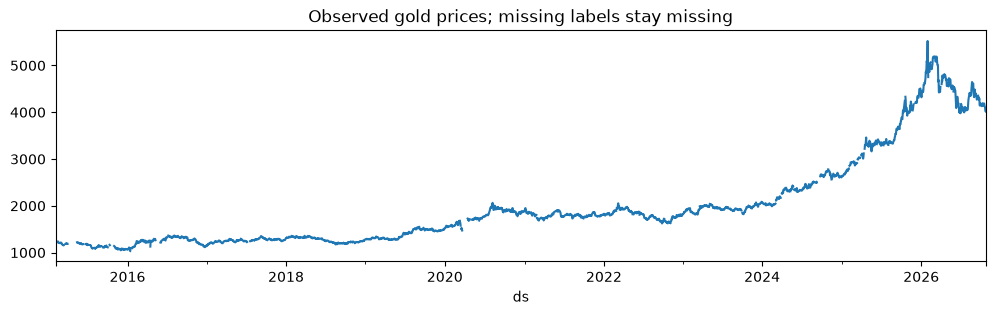

In [22]:
# Confirm external regressors are available at each forecast origin.
columns = feature_columns(features, 'external', KIND)
display(features[columns].isna().mean().rename('missing_fraction').to_frame())
panel.y.plot(figsize=(12, 3), title='Observed gold prices; missing labels stay missing')
plt.show()

## 4. Run nested walk-forward development evaluation
This cell performs actual training and may take time. Each fold reports inner candidate scores,
selects a configuration, refits it, and predicts the outer block. Forecasting uses only information
available at each origin. Outer labels are used only for scoring.

For a quick installation check, use one fold and one candidate. Restore the full settings before
comparing models or making performance claims.

In [23]:
# Full defaults: five outer folds and all candidates above.
cv_folds = folds
# Full training; results are checkpointed to artifacts/<kind>/ after each fold.
cv_predictions, cv_metrics, selections = run_cross_validation(
    KIND, panel, features, cv_folds, cfg, trials=trials)
display(cv_metrics)
display(selections)

prophet: cv_1; train through 2023-06-08


19:41:59 - cmdstanpy - INFO - Chain [1] start processing
19:41:59 - cmdstanpy - INFO - Chain [1] done processing


  candidate 1/3: inner MAE=96.584


19:41:59 - cmdstanpy - INFO - Chain [1] start processing
19:42:01 - cmdstanpy - INFO - Chain [1] done processing


  candidate 2/3: inner MAE=54.279


19:42:02 - cmdstanpy - INFO - Chain [1] start processing
19:42:03 - cmdstanpy - INFO - Chain [1] done processing


... (32 outputs left out)

  candidate 3/3: inner MAE=127.964


19:42:30 - cmdstanpy - INFO - Chain [1] start processing
19:42:31 - cmdstanpy - INFO - Chain [1] done processing


,model,fold,horizon,n,MAE,RMSE,MAPE,MASE,baseline_MAE,skill_vs_persistence
0,prophet,cv_1,1,5,36.619167,54.734617,1.850046,3.804878,9.580000,-2.822460
1,prophet,cv_1,5,5,35.385345,49.524756,1.798560,3.676679,19.620000,-0.803534
2,prophet,cv_1,20,4,36.693062,49.672282,1.865918,3.812556,22.650000,-0.620003
3,prophet,cv_2,1,5,93.389570,111.627646,4.545434,9.745008,11.254000,-7.298345
4,prophet,cv_2,5,4,91.337430,113.358529,4.461577,9.530872,46.242500,-0.975184
5,prophet,cv_2,20,6,134.043219,156.829129,6.142310,13.987132,76.023333,-0.763185
6,prophet,cv_3,1,4,258.734312,287.779256,10.188900,26.516004,13.507500,-18.154863
7,prophet,cv_3,5,4,215.996715,272.872750,8.429449,22.136105,26.272500,-7.221399
8,prophet,cv_3,20,4,226.704686,248.131213,9.043021,23.233495,55.287500,-3.100469
9,prophet,cv_4,1,4,84.285716,88.457389,3.061701,8.383519,26.072500,-2.232744


,candidate,inner_MAE,params,fold
0,0,96.583550,"{""group"": ""gold_only"", ""changepoint_prior_scal...",cv_1
1,1,54.279142,"{""group"": ""external"", ""changepoint_prior_scale...",cv_1
2,2,65.012182,"{""group"": ""external"", ""changepoint_prior_scale...",cv_1
3,0,150.021834,"{""group"": ""gold_only"", ""changepoint_prior_scal...",cv_2
4,1,36.232525,"{""group"": ""external"", ""changepoint_prior_scale...",cv_2
5,2,39.438968,"{""group"": ""external"", ""changepoint_prior_scale...",cv_2
6,0,95.354412,"{""group"": ""gold_only"", ""changepoint_prior_scal...",cv_3
7,1,106.256740,"{""group"": ""external"", ""changepoint_prior_scale...",cv_3
8,2,112.283134,"{""group"": ""external"", ""changepoint_prior_scale...",cv_3
9,0,233.811904,"{""group"": ""gold_only"", ""changepoint_prior_scal...",cv_4


## 5. Review errors by horizon, baseline skill, and prediction bias

,MAE,RMSE,MAPE,MASE,skill_vs_persistence
horizon,,,,,
1,118.843152,139.068136,4.587412,11.986039,-6.568094
5,130.778144,160.627579,4.842481,13.122566,-2.092965
20,137.394878,167.634261,5.063176,13.817877,-0.881585


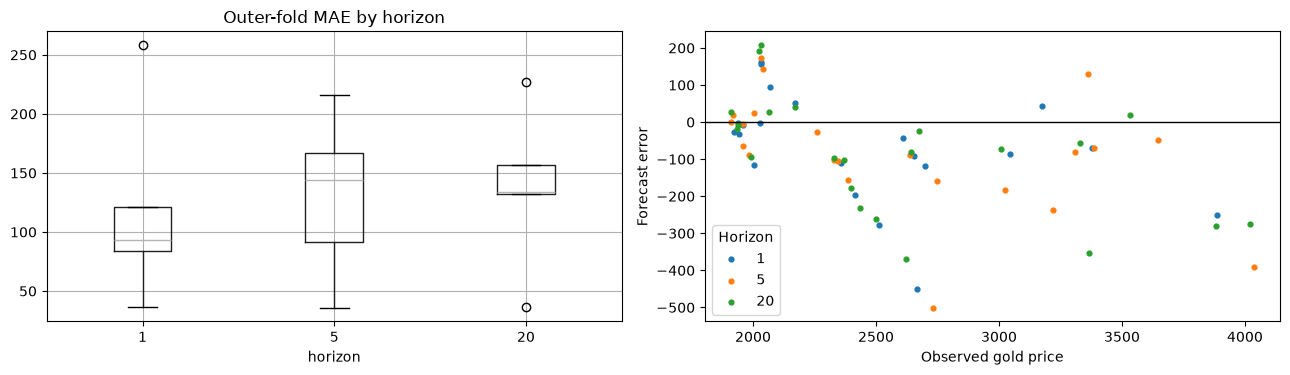

In [24]:
# Summarize outer error by horizon and check prediction bias per model.
display(cv_metrics.groupby('horizon')[['MAE', 'RMSE', 'MAPE', 'MASE', 'skill_vs_persistence']].mean())
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
cv_metrics.boxplot(column='MAE', by='horizon', ax=axes[0])
axes[0].set_title('Outer-fold MAE by horizon')
for horizon, group in cv_predictions.groupby('horizon'):
    observed = group.dropna(subset=['actual'])
    axes[1].scatter(observed.actual, observed.prediction - observed.actual, s=12, label=str(horizon))
axes[1].axhline(0, color='black', linewidth=1)
axes[1].set_xlabel('Observed gold price')
axes[1].set_ylabel('Forecast error')
axes[1].legend(title='Horizon')
plt.suptitle('')
plt.tight_layout()

## 6. Plot development forecasts against observed prices

These figures use the fixed-origin predictions from each outer fold:
1. full observed history with every outer prediction;
2. actual vs forecast for each horizon;
3. training context plus test block per fold;
4. actual vs predicted price per horizon.
Each plot is also saved to `artifacts/<model>/plots/`.

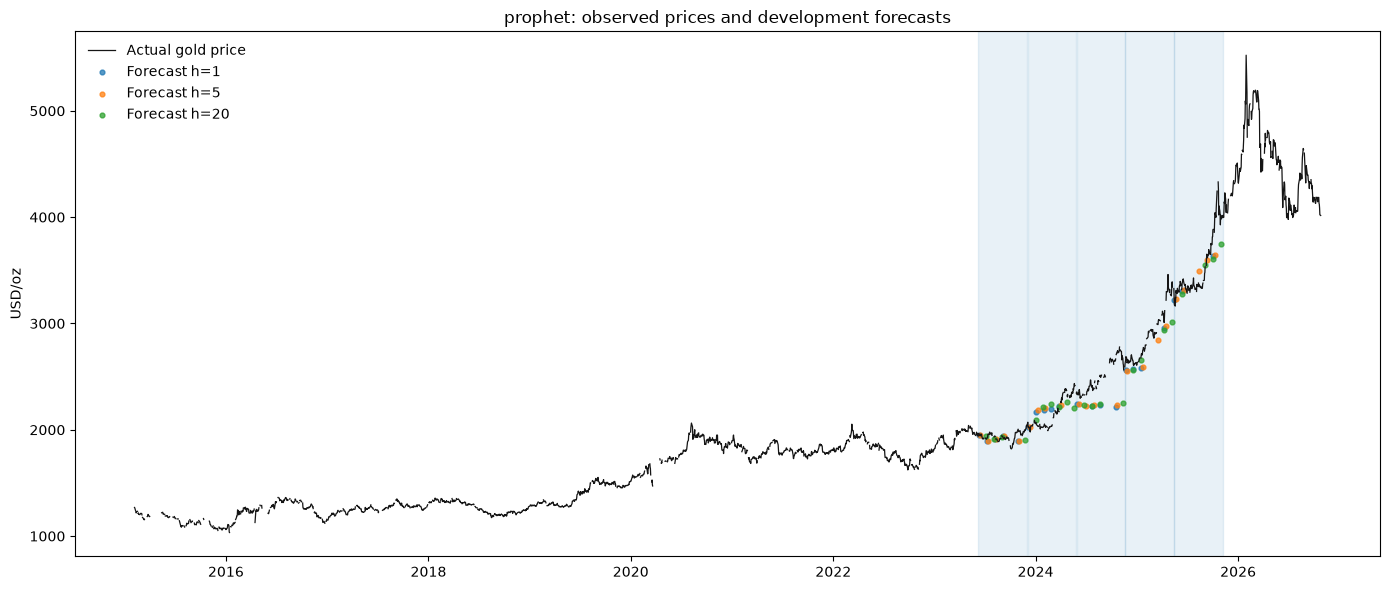

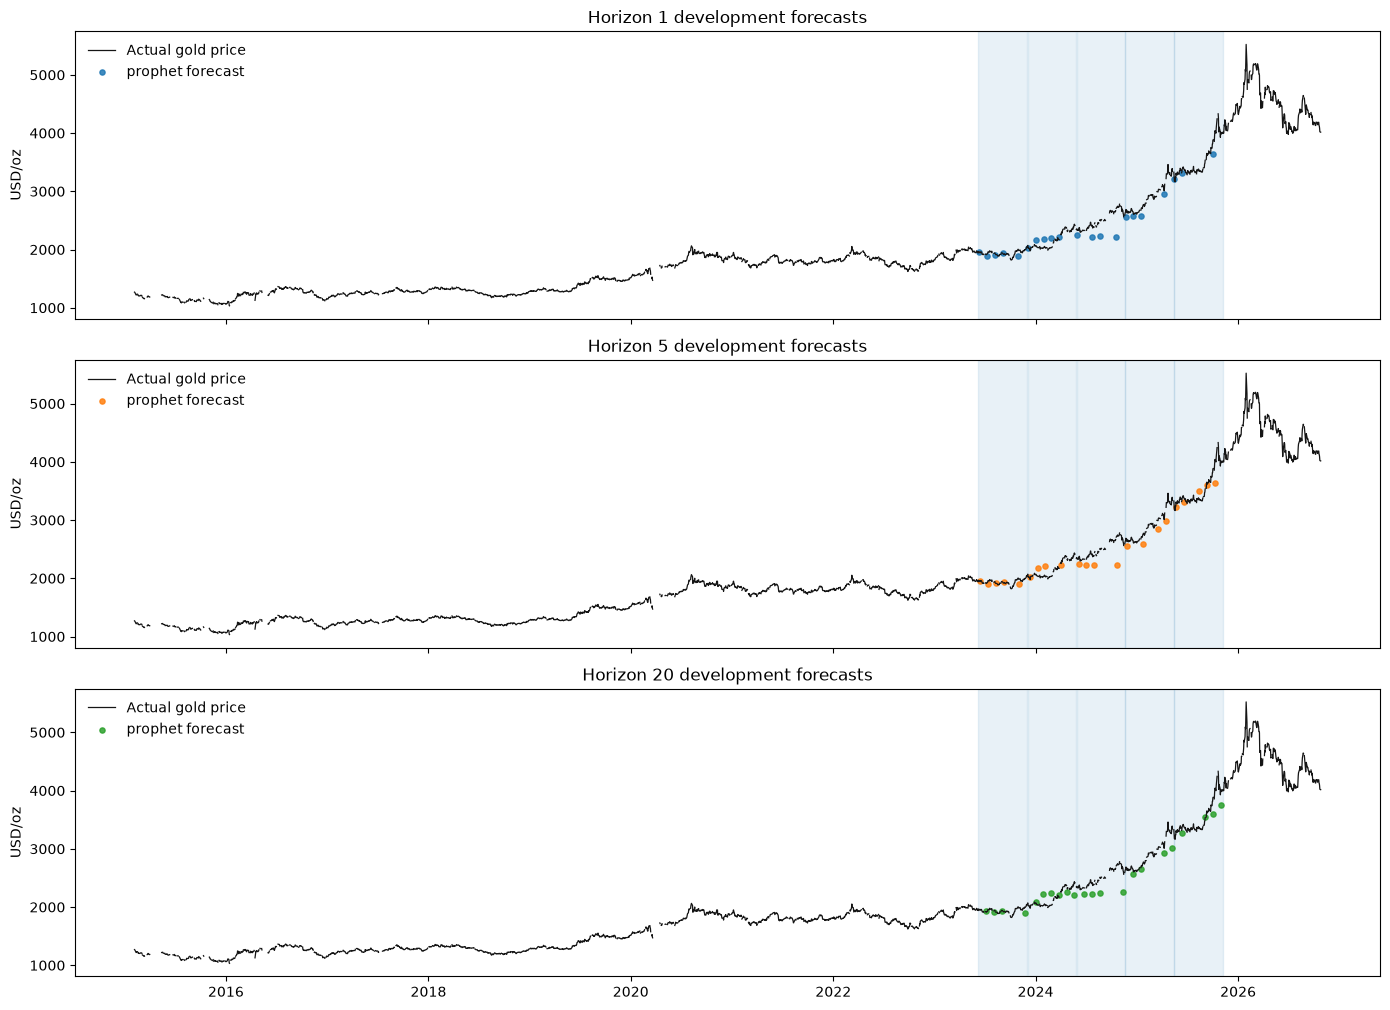

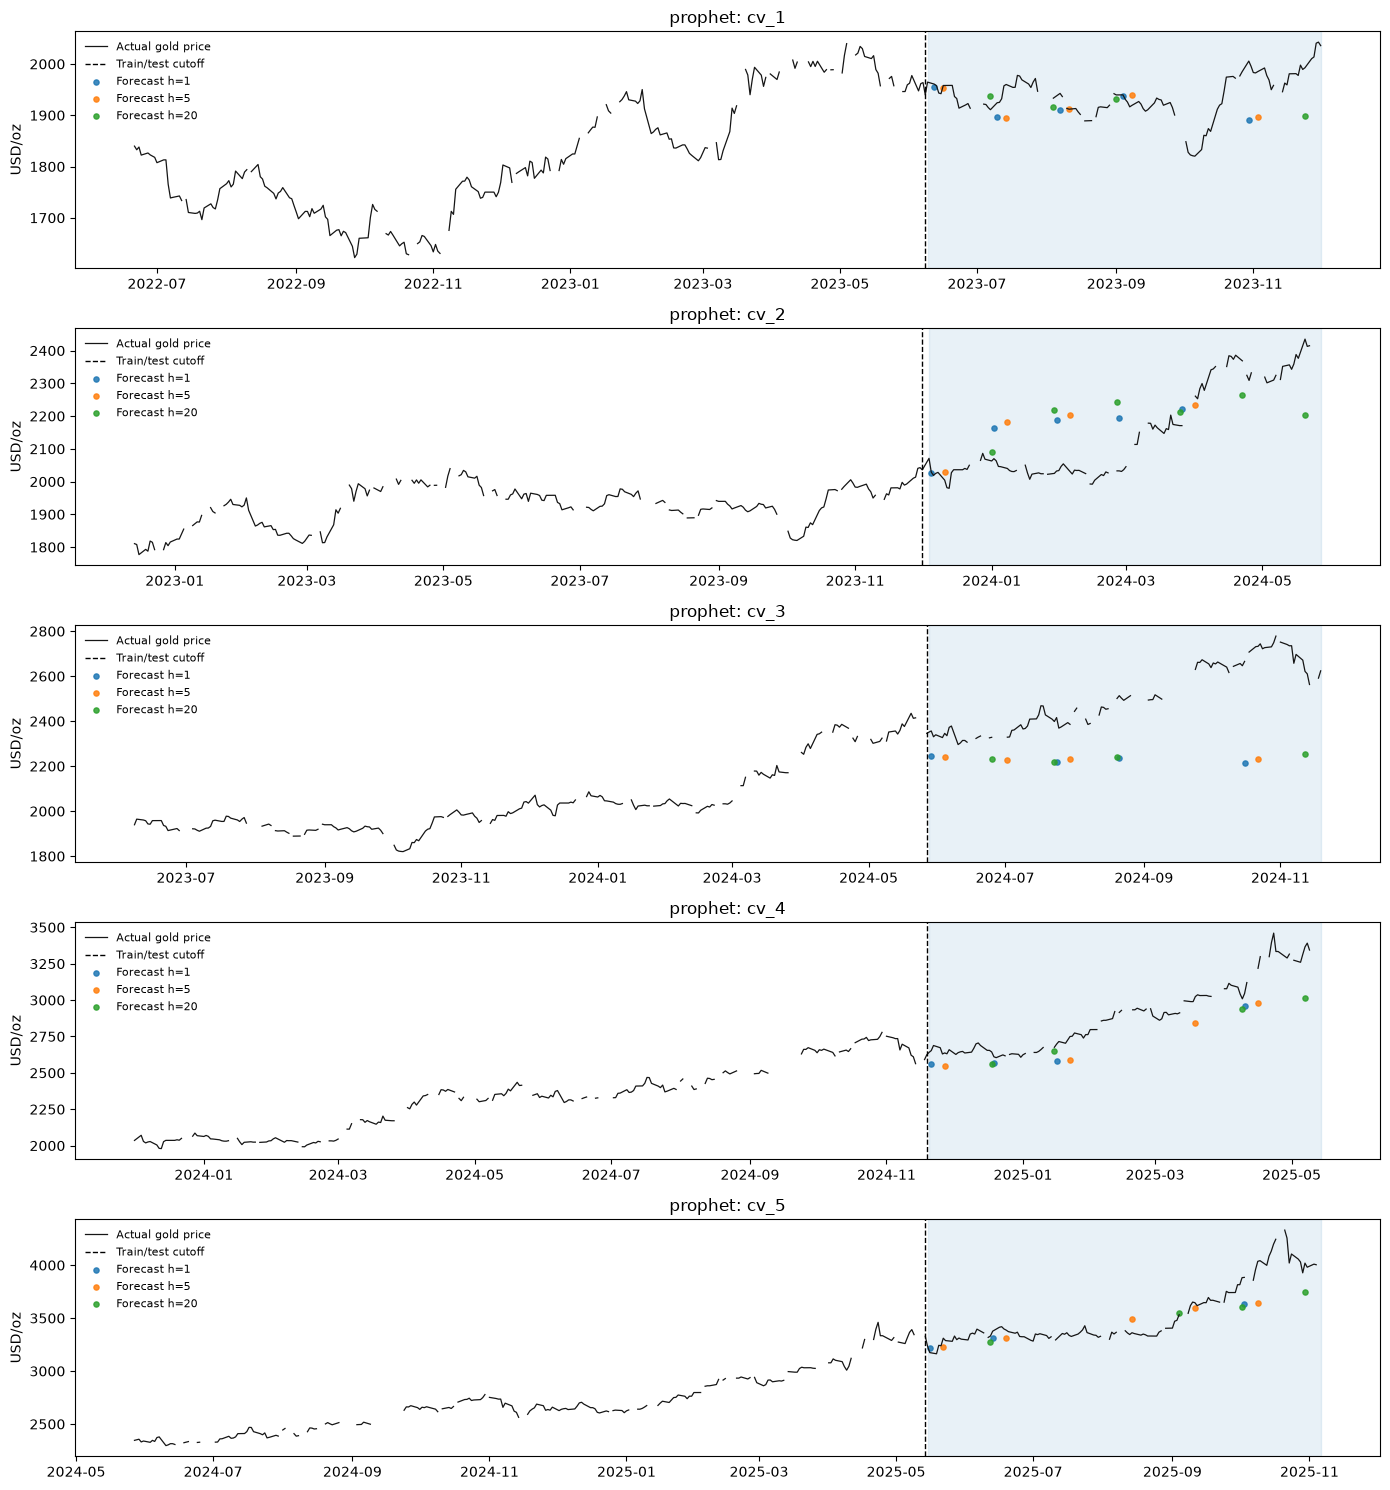

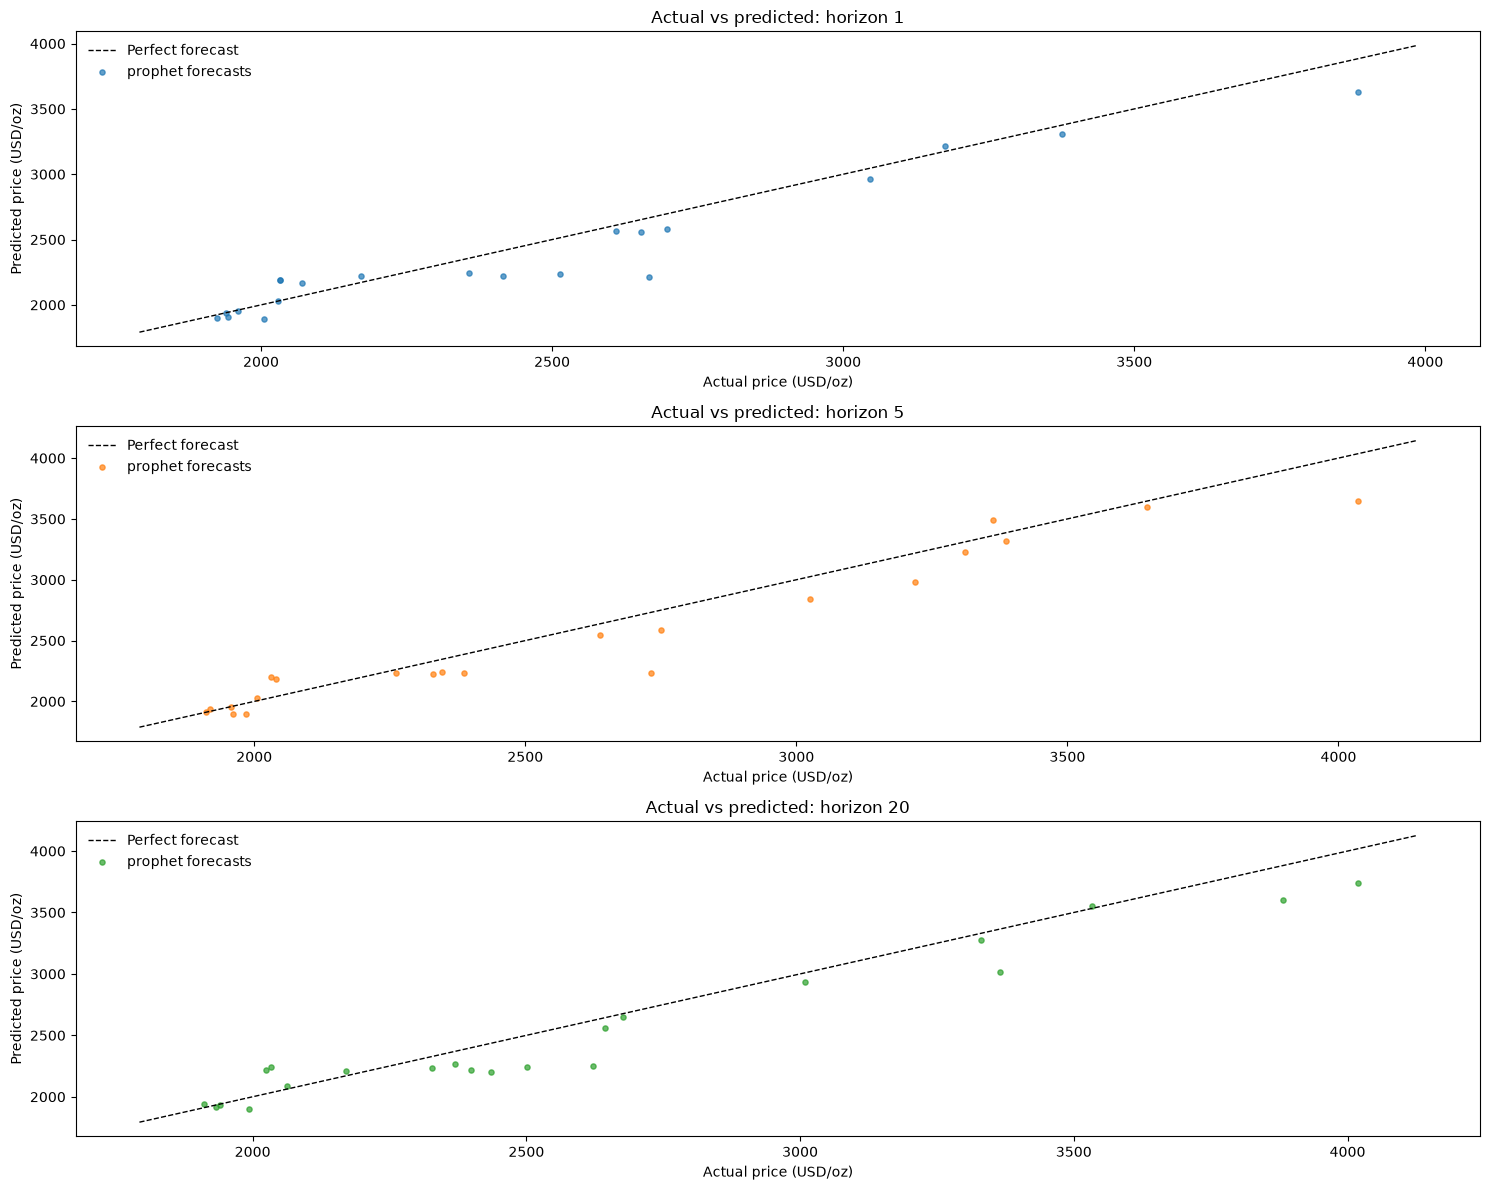

[PosixPath('/home/kosala/git-repos/exps/gold_forecasting/artifacts/prophet/plots/actual_and_forecasts_timeline.png'),
 PosixPath('/home/kosala/git-repos/exps/gold_forecasting/artifacts/prophet/plots/actual_and_forecasts_by_horizon.png'),
 PosixPath('/home/kosala/git-repos/exps/gold_forecasting/artifacts/prophet/plots/actual_and_forecasts_by_fold.png'),
 PosixPath('/home/kosala/git-repos/exps/gold_forecasting/artifacts/prophet/plots/actual_vs_predicted_scatter.png')]

In [25]:
from gold_plot_utils import plot_model_cv

plot_model_cv(panel, cv_predictions, folds, KIND, cfg, ROOT / 'artifacts' / KIND)

## 7. Holdout is intentionally skipped
This run produces future forecasts only. `final_holdout_enabled` stays false, so
no holdout scoring or model ranking is performed. The next cell simply reports
that the holdout was not evaluated.

In [26]:
# Load the shared experiment configuration.
cfg = load_config()
# Holdout runs once, and parameters are locked before its results are scored.
if cfg['final_holdout_enabled']:
    holdout_predictions, holdout_metrics, locked_parameters = evaluate_holdout(
        KIND, panel, features, folds, cfg, trials=trials)
    display(holdout_metrics)
    display(locked_parameters)
else:
    print('Holdout not evaluated; this is a forecast-only run.')

19:42:36 - cmdstanpy - INFO - Chain [1] start processing
19:42:37 - cmdstanpy - INFO - Chain [1] done processing


  candidate 1/3: inner MAE=381.796


19:42:38 - cmdstanpy - INFO - Chain [1] start processing
19:42:39 - cmdstanpy - INFO - Chain [1] done processing


  candidate 2/3: inner MAE=138.762


19:42:40 - cmdstanpy - INFO - Chain [1] start processing
19:42:42 - cmdstanpy - INFO - Chain [1] done processing


  candidate 3/3: inner MAE=140.762


19:42:42 - cmdstanpy - INFO - Chain [1] start processing
19:42:45 - cmdstanpy - INFO - Chain [1] done processing


,model,fold,horizon,n,MAE,RMSE,MAPE,MASE,baseline_MAE,skill_vs_persistence
0,prophet,holdout,1,11,421.649937,519.385348,9.528129,36.192103,58.936364,-6.154326
1,prophet,holdout,5,9,545.773699,583.445499,12.257678,46.846201,162.440000,-2.359848
2,prophet,holdout,20,12,578.123729,696.284999,12.663062,49.622949,338.485000,-0.707974


{'group': 'external', 'changepoint_prior_scale': 0.05}

## 8. Refit the locked model and generate future forecasts
Run when locked parameters exist. The forecast starts from the latest observed gold quote.
Only the configured horizons are returned. Prophet uses auxiliary future external paths; other models keep origin-time features.
Artifacts include the fitted model, input feature names, preprocessing where applicable,
locked configuration, predictions and metrics. No calibrated uncertainty intervals are claimed.

In [27]:
locked = ROOT / 'artifacts' / KIND / 'locked_parameters.json'
if locked.exists():
    # Refit reuses the locked configuration from artifacts/<kind>/locked_parameters.json.
    future_forecast = refit_and_forecast(KIND, panel, features, cfg)
    display(future_forecast)
else:
    print('Final refit waits for the parameter-lock stage.')

19:42:45 - cmdstanpy - INFO - Chain [1] start processing
19:42:47 - cmdstanpy - INFO - Chain [1] done processing


,origin,horizon,target_date,forecast,model
0,2026-10-26,1,2026-10-27,4599.214981,prophet
1,2026-10-26,5,2026-11-02,4645.835910,prophet
2,2026-10-26,20,2026-11-23,4668.473738,prophet


## 9. Optional holdout and future forecast plots

These figures appear only when the matching artifacts exist:
- `artifacts/<model>/holdout_predictions.csv` after a locked holdout run;
- `artifacts/<model>/future_forecast.csv` after the final refit.

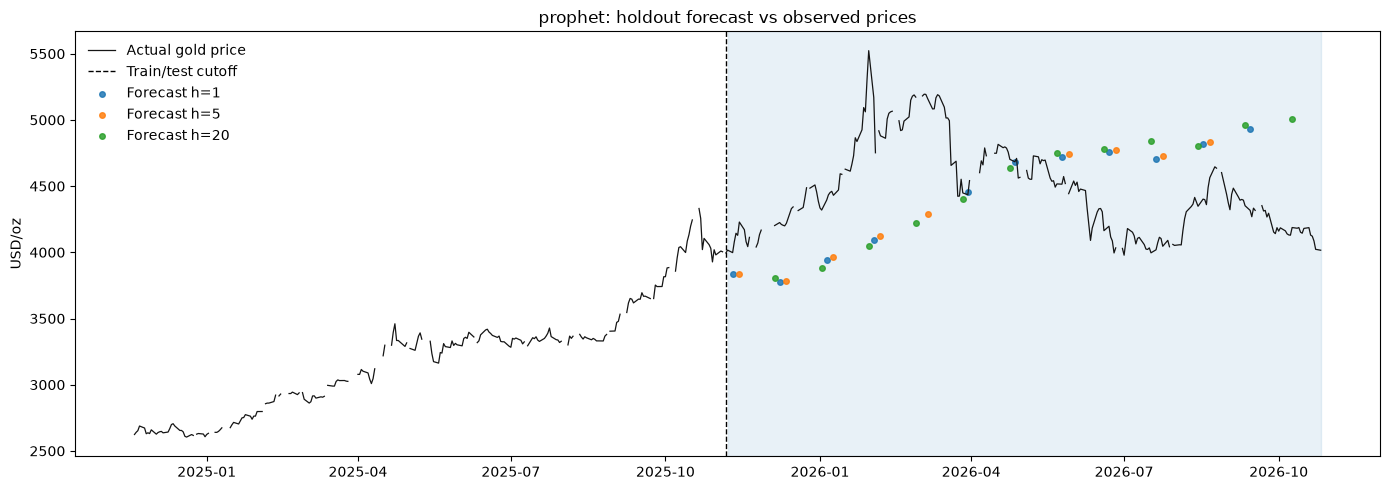

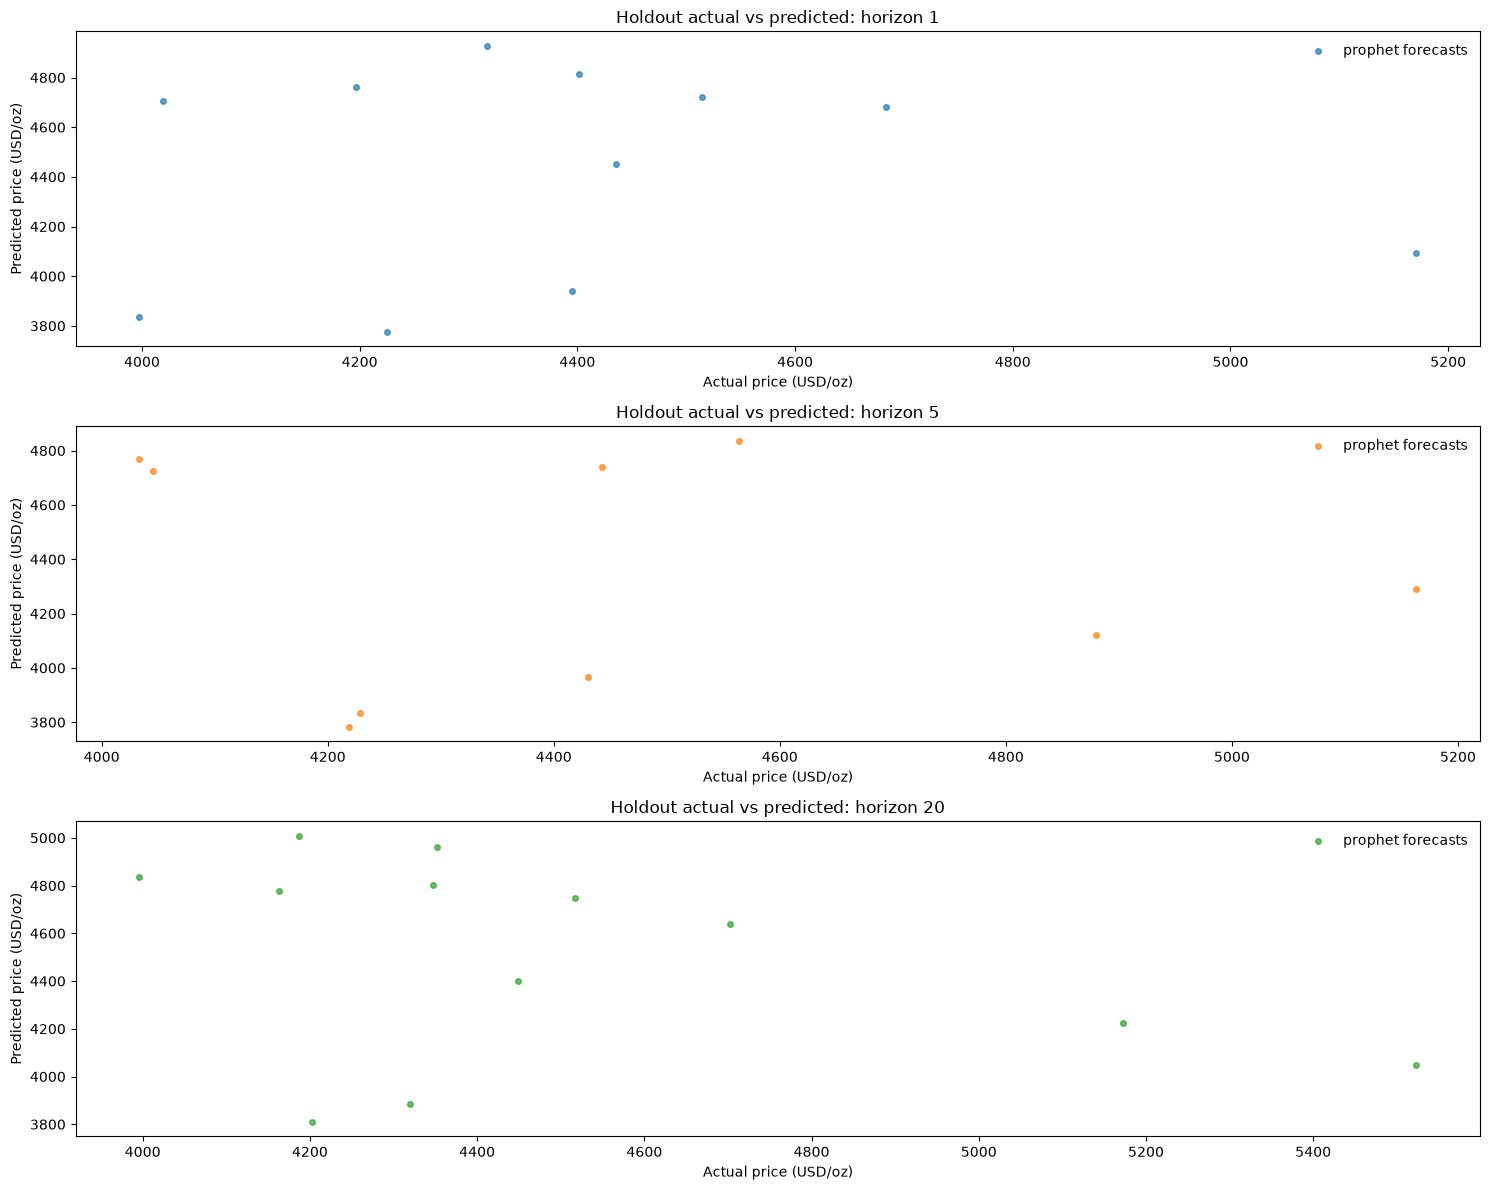

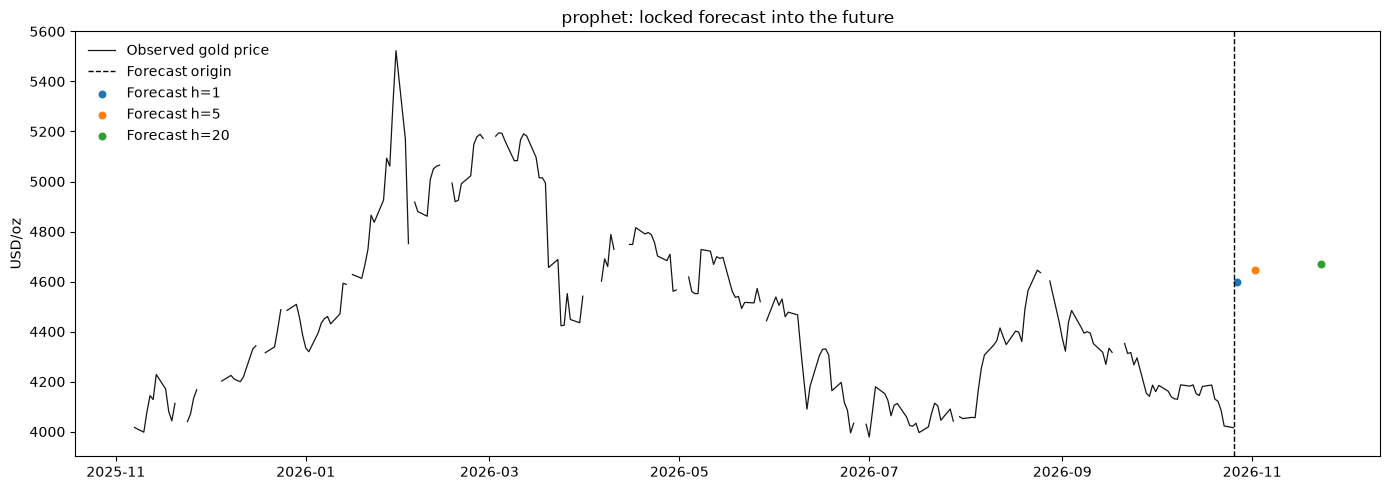

In [28]:
from gold_plot_utils import plot_model_holdout, plot_future_forecast

out_dir = ROOT / 'artifacts' / KIND
holdout_path = out_dir / 'holdout_predictions.csv'
future_path = out_dir / 'future_forecast.csv'
if holdout_path.exists():
    holdout_predictions = pd.read_csv(holdout_path, parse_dates=['origin', 'target_date'])
    plot_model_holdout(panel, holdout_predictions, folds, KIND, cfg, out_dir)
else:
    print('No holdout predictions yet.')
if future_path.exists():
    future_forecast = pd.read_csv(future_path, parse_dates=['origin', 'target_date'])
    plot_future_forecast(panel, future_forecast, KIND, cfg, out_dir)
else:
    print('No future forecast yet.')